# Starbucks Drinks Nutrition EDA & Decision Tree Classification
We will start by loading the dataset, checking its columns, and summarizing the basic statistics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/starbucks-menu-nutrition-drinks.csv'
df = pd.read_csv(file_path)

# Display basic information and first few rows
print("Dataset Shape:", df.shape)
display(df.info())
display(df.head())

Dataset Shape: (177, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  177 non-null    object
 1   Calories    177 non-null    object
 2   Fat (g)     177 non-null    object
 3   Carb. (g)   177 non-null    object
 4   Fiber (g)   177 non-null    object
 5   Protein     177 non-null    object
 6   Sodium      177 non-null    object
dtypes: object(7)
memory usage: 9.8+ KB


None

,Unnamed: 0,Calories,Fat (g),Carb. (g),Fiber (g),Protein,Sodium
0,Cool Lime Starbucks Refreshers™ Beverage,45,0,11,0,0,10
1,Ombré Pink Drink,-,-,-,-,-,-
2,Pink Drink,-,-,-,-,-,-
3,Strawberry Acai Starbucks Refreshers™ Beverage,80,0,18,1,0,10
4,Very Berry Hibiscus Starbucks Refreshers™ Beve...,60,0,14,1,0,10


Let's clean the dataset (handling missing values, parsing numeric columns) and prepare a classification target. Since this dataset contains various nutritional values, we can create a classification target (for example, predicting whether a drink is High Calorie or Low Calorie based on its other nutrition stats, or classifying drink categories if available).

In [2]:
# Clean columns if they contain non-numeric symbols (like empty strings, '-', or dashes)
# Let's inspect the column names first
print("Columns:", df.columns.tolist())

# We will replace '-' or empty strings with NaN and convert columns to float where appropriate
for col in df.columns:
    if col != df.columns[0]: # Skip the drink name/category column
        df[col] = df[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing values with the median of each column
df = df.fillna(df.median(numeric_only=True))

# Display summary statistics
display(df.describe())

Columns: ['Unnamed: 0', 'Calories', 'Fat (g)', 'Carb. (g)', 'Fiber (g)', 'Protein', 'Sodium']


,Calories,Fat (g),Carb. (g),Fiber (g),Protein,Sodium
count,177.000000,177.000000,177.00000,177.000000,177.000000,177.000000
mean,132.683616,1.214689,25.10452,0.231638,2.638418,37.316384
std,67.535777,3.030941,10.94701,1.043113,4.386743,53.671999
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,130.000000,0.000000,24.00000,0.000000,0.000000,10.000000
50%,130.000000,0.000000,25.50000,0.000000,1.000000,15.000000
75%,140.000000,0.000000,27.00000,0.000000,1.000000,15.000000
max,430.000000,26.000000,64.00000,8.000000,20.000000,240.000000


Now, we will define a classification target. Let's classify drinks into 'High Calories' (1) and 'Low Calories' (0) based on the median calorie threshold, and train a Decision Tree Classifier to predict this category using the remaining nutritional features.

Using 'Calories' as the base for our target. Median value: 130.0

Decision Tree Accuracy: 0.9722

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        25
           1       0.92      1.00      0.96        11

    accuracy                           0.97        36
   macro avg       0.96      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



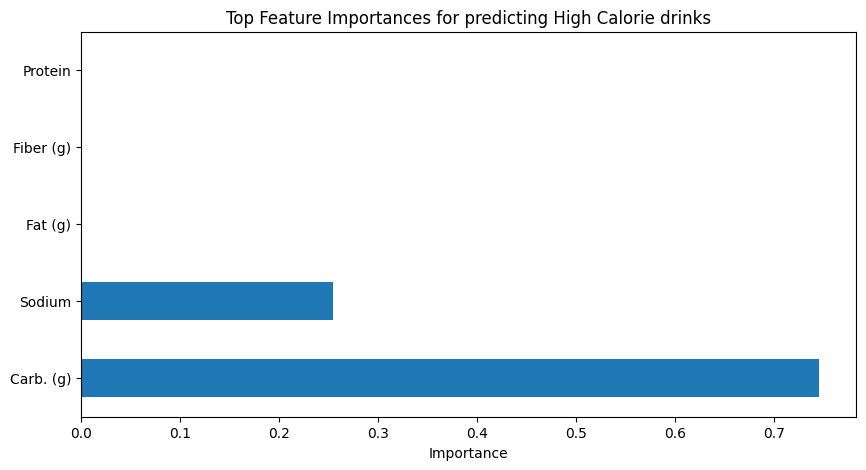

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Let's find the column that represents Calories
calorie_col = [col for col in df.columns if 'calorie' in col.lower()]

if calorie_col:
    target_col = calorie_col[0]
    median_calories = df[target_col].median()
    print(f"Using '{target_col}' as the base for our target. Median value: {median_calories}")

    # Create binary target: 1 if above median, 0 otherwise
    df['Is_High_Calorie'] = (df[target_col] > median_calories).astype(int)

    # Features (X) will be all other numeric nutrition columns except the target-related ones and name
    feature_cols = [col for col in df.select_dtypes(include=[np.number]).columns
                    if col not in ['Is_High_Calorie', target_col]]

    X = df[feature_cols]
    y = df['Is_High_Calorie']

    # Split data into Train and Test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize and train Decision Tree Classifier
    clf = DecisionTreeClassifier(max_depth=4, random_state=42)
    clf.fit(X_train, y_train)

    # Make predictions
    y_pred = clf.predict(X_test)

    # Calculate Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print(f"\nDecision Tree Accuracy: {accuracy:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Plot Feature Importances
    plt.figure(figsize=(10, 5))
    feat_importances = pd.Series(clf.feature_importances_, index=feature_cols)
    feat_importances.nlargest(10).plot(kind='barh')
    plt.title('Top Feature Importances for predicting High Calorie drinks')
    plt.xlabel('Importance')
    plt.show()
else:
    print("Could not find a calorie column to create a target variable.")

### Evaluating Model Predictions on 10 Sample Drinks
Let's pull 10 sample drinks from the test dataset, predict whether they are High Calorie or Low Calorie, and compare the model's predictions with the actual classifications.

In [4]:
# Take a sample of 10 drinks from the test set
sample_indices = X_test.head(10).index

sample_features = X_test.loc[sample_indices]
sample_actuals = y_test.loc[sample_indices]
sample_names = df.loc[sample_indices, 'Unnamed: 0'] # Use the original drink name column

# Generate predictions for these 10 samples
sample_predictions = clf.predict(sample_features)

# Combine into a comparative DataFrame
comparison_df = pd.DataFrame({
    'Drink Name': sample_names,
    'Actual Label (1=High Cal, 0=Low Cal)': sample_actuals,
    'Predicted Label (1=High Cal, 0=Low Cal)': sample_predictions
})

# Map labels to readable text for better presentation
comparison_df['Actual Category'] = comparison_df['Actual Label (1=High Cal, 0=Low Cal)'].map({1: 'High Calorie', 0: 'Low Calorie'})
comparison_df['Predicted Category'] = comparison_df['Predicted Label (1=High Cal, 0=Low Cal)'].map({1: 'High Calorie', 0: 'Low Calorie'})

display(comparison_df[['Drink Name', 'Actual Category', 'Predicted Category']])

,Drink Name,Actual Category,Predicted Category
19,Tazo® Bottled Berry Blossom White,Low Calorie,Low Calorie
45,Starbucks Doubleshot® Energy Mexican Mocha,Low Calorie,Low Calorie
139,White Chocolate Mocha,High Calorie,High Calorie
30,Tazo® Bottled Tazoberry,High Calorie,High Calorie
67,Starbucks® Caramel Iced Coffee,Low Calorie,Low Calorie
16,Starbucks® Low Calorie Iced Coffee + Milk,Low Calorie,Low Calorie
119,Espresso,Low Calorie,Low Calorie
173,Strawberry Smoothie,High Calorie,High Calorie
109,Hot Chocolate,High Calorie,High Calorie
140,Caffè Vanilla Frappuccino® Blended Coffee,Low Calorie,Low Calorie


### Saving the Decision Tree Model
We will save our trained Decision Tree model (`clf`) to a file named `starbucks_dt_model.joblib` using the `joblib` library.

In [5]:
import joblib

# Save the model to a file
model_filename = 'starbucks_dt_model.joblib'
joblib.dump(clf, model_filename)

print(f"Model successfully saved as: {model_filename}")

Model successfully saved as: starbucks_dt_model.joblib
